## Exercises from the book "Pricing and Revenue Optimization" (Robert L. Phillips, 2nd ed., 2021)

### Chapter 4 - Estimating Price Response

#### Exercise 1:
For the three price-response functions listed in Table 4.4—linear, exponential, 
and constant-elasticity—fit a model on the training data in Table 4.2 that includes 
Weekend as an explanatory variable along with Price.

a. What are the coefficients for Price and Weekend in each model?

b. Calculate RMSE, MAPE, and weighted MAPE for the models on the test data in 
Table 4.3 including Weekend. How do the fits of the models including Weekend 
compare to the fits of the previous models? Which model best fits the data?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

In [2]:
# Importing the training and test datasets as pandas DataFrames
train_set = pd.read_csv("table4.2.csv")
test_set = pd.read_csv("table4.3.csv")

# Displaying the first 10 rows of the training and test datasets for verification
print("Number of rows and columns:", train_set.shape)
print(train_set.head(10))
print("Number of rows and columns:", test_set.shape)
print(test_set.head(10))

Number of rows and columns: (42, 5)
   day  price  sales  weekend  potential
0    1   6.45     49        1         52
1    2   6.55     40        1         41
2    3   6.65     24        0         31
3    4   6.75     25        0         34
4    5   6.85     18        0         27
5    6   6.95     31        0         49
6    7   7.05     17        0         37
7    8   7.15     19        1         52
8    9   7.25      4        1         22
9   10   7.15     11        0         37
Number of rows and columns: (21, 5)
   day  price  sales  weekend  potential
0    1   6.45     52        1         56
1    2   6.55     49        1         55
2    3   6.65     34        0         39
3    4   6.75     15        0         27
4    5   6.85     17        0         27
5    6   6.95     17        0         22
6    7   7.05      6        0         32
7    8   7.15     24        1         66
8    9   7.25     15        1         42
9   10   7.15     13        0         30


The three price-response functions are

* Linear: $d(p) = D(1-bp)^+$
* Exponential: $d(p) = De^{-bp}$
* Constant-elasticity: $d(p) = Ap^{-\varepsilon}$


First let's fit the three models on the training set with just price and sales:

In [ ]:
# Creating variables for the training set data
X_train = train_set[["price"]]
y_train = train_set["sales"]
X_log_train = np.log(X_train)
y_log_train = np.log(y_train)

In [4]:
print("Linear model")

# Fitting a linear regression to the linear model training data
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Getting the coefficients of the linear regression
print("Intercept:", linear_model.intercept_)
print("Slope:", linear_model.coef_[0])

# Finding the parameters D and b of the linear model
D_lin = linear_model.intercept_
print("D =", D_lin)
b_lin = - linear_model.coef_[0] / D_lin
print("b =", b_lin)

# Finding the R-squared value of the linear regression model on the training data
r_squared_lin = linear_model.score(X_train, y_train)
print("R-squared:", r_squared_lin)

Linear model
Intercept: 222.01920087775446
Slope: -29.496205540824725
D = 222.01920087775446
b = 0.1328543000975198
R-squared: 0.3500653339515143


In [5]:
print("Exponential model")

# Fitting a linear regression to the exponential model training data
exponential_model = LinearRegression()
exponential_model.fit(X_train, y_log_train)

# Getting the coefficients of the linear regression
print("Intercept:", exponential_model.intercept_)
print("Slope:", exponential_model.coef_[0])

# Finding the parameters D and b of the exponential model
D_exp = np.exp(exponential_model.intercept_)
print("D =", D_exp)
b_exp = - exponential_model.coef_[0]
print("b =", b_exp)

# Finding the R-squared value of the exponential linear regression on the training data
r_squared_exp = exponential_model.score(X_train, y_log_train)
print("R-squared:", r_squared_exp)


Exponential model
Intercept: 15.649337437028873
Slope: -1.8847829000952538
D = 6257788.694799975
b = 1.8847829000952538
R-squared: 0.3316951616726187


In [6]:
print("Constant Elasticity model")

# Fitting a linear regression to the constant elasticity model training data
constant_elasticity_model = LinearRegression()
constant_elasticity_model.fit(X_log_train, y_log_train)

# Getting the coefficients of the linear regression
print("Intercept:", constant_elasticity_model.intercept_)
print("Slope:", constant_elasticity_model.coef_[0])

# Finding the parameters A and epsilon of the constant elasticity model
A = np.exp(constant_elasticity_model.intercept_)
print("A =", A)
epsilon = - constant_elasticity_model.coef_[0]
print("epsilon =", epsilon)

# Finding the R-squared value of the constant elasticity linear regression on the training data
r_squared_ce = constant_elasticity_model.score(X_log_train, y_log_train)
print("R-squared:", r_squared_ce)

Constant Elasticity model
Intercept: 27.40116746549102
Slope: -12.821217118665512
A = 794649890657.5829
epsilon = 12.821217118665512
R-squared: 0.3260404685629025


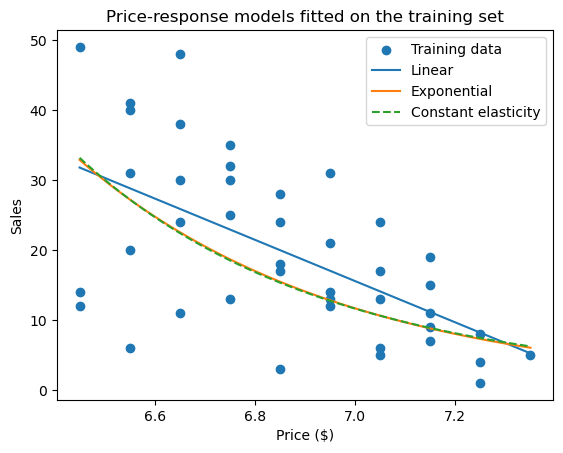

In [7]:
# Creating a range of prices for plotting the fitted models
prices = np.linspace(train_set["price"].min(), train_set["price"].max(), 100)

# Linear model
linear_curve = D_lin * (1 - b_lin * prices)

# Exponential model: back to actual demand
exp_curve = D_exp * np.exp(-b_exp * prices)

# Constant elasticity model: back to actual demand
ce_curve = A * prices ** (-epsilon)

plt.scatter(train_set["price"], train_set["sales"], label="Training data")
plt.plot(prices, linear_curve, label="Linear")
plt.plot(prices, exp_curve, label="Exponential")
plt.plot(prices, ce_curve, linestyle="--", label="Constant elasticity")
plt.xlabel("Price ($)")
plt.ylabel("Sales")
plt.title("Price-response models fitted on the training set")
plt.legend()
plt.show()

Now let's test the models on the test set:

In [12]:
# Creating variables for the test set data

X_test = test_set[["price"]]
y_test = test_set["sales"]
X_log_test = np.log(X_test)
y_log_test = np.log(y_test) # (not used in the following code)

In [13]:
# Creating the predictions for the test set data for each model
linear_predictions = linear_model.predict(X_test)
exponential_predictions = np.exp(exponential_model.predict(X_test))
constant_elasticity_predictions = np.exp(constant_elasticity_model.predict(X_log_test))

# Creating a predictions table to compare the actual sales and the predictions from each model
predictions_table = pd.DataFrame({
    "day": test_set["day"],
    "actual sales": test_set["sales"],
    "linear predictions": linear_predictions,
    "exponential predictions": exponential_predictions,
    "constant elasticity predictions": constant_elasticity_predictions
})
predictions_table.round(2)

,day,actual sales,linear predictions,exponential predictions,constant elasticity predictions
0,1,52,31.77,32.87,33.16
1,2,49,28.82,27.22,27.23
2,3,34,25.87,22.55,22.42
3,4,15,22.92,18.67,18.51
4,5,17,19.97,15.46,15.33
5,6,17,17.02,12.81,12.73
6,7,6,14.07,10.61,10.60
7,8,24,11.12,8.79,8.85
8,9,15,8.17,7.28,7.41
9,10,13,11.12,8.79,8.85


And evaluate the predictions using three metrics: